In [1]:
# -*- coding: utf-8 -*-
# NOTEBOOK : TEST MODÈLES DE BASE SUR 94 FEATURES (SANS ÉQUILIBRAGE EXPLICITE)

# =============================================================================
# CELLULE 1 : IMPORTS ET CONFIGURATION
# =============================================================================
print("--- Cellule 1: Imports et Configuration ---")

# --- Imports ---
import pandas as pd
import numpy as np
import os
from datetime import datetime
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from collections import Counter

# Sklearn - Preprocessing, Model Selection, Metrics, Models
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_auc_score,
    precision_recall_curve, auc, average_precision_score
)

# Supprimer les avertissements pour une sortie plus propre (optionnel)
# warnings.filterwarnings('ignore')

# --- Configuration des Chemins et Variables ---
DATA_PATH = "/home/kaoutar/Desktop/data/"
# !! VÉRIFIEZ ET ADAPTEZ CE NOM DE FICHIER !!
# Doit être le fichier CSV contenant vos 94 features assainies/enrichies + la cible 'appetent'
INPUT_FILE = os.path.join(DATA_PATH, 'dataset_X94_clean_enhanced.csv')

TARGET_COL_NAME = 'appetent'
RANDOM_STATE = 42
# ---------------------------------------------

print("-" * 50)
print("Imports et Configuration de Base Terminés.")
print(f"Utilisation du fichier d'entrée : {INPUT_FILE}")
print(f"Colonne Cible Attendue : {TARGET_COL_NAME}")
print(f"Aucune méthode d'équilibrage explicite ne sera appliquée.")
print("-" * 50)

# --- FIN Cellule 1 ---

--- Cellule 1: Imports et Configuration ---
--------------------------------------------------
Imports et Configuration de Base Terminés.
Utilisation du fichier d'entrée : /home/kaoutar/Desktop/data/dataset_X94_clean_enhanced.csv
Colonne Cible Attendue : appetent
Aucune méthode d'équilibrage explicite ne sera appliquée.
--------------------------------------------------


In [2]:
# =============================================================================
# CELLULE 2 : CHARGEMENT DES DONNÉES (94 features) ET PRÉPARATION X, y
# =============================================================================
print(f"\n--- Chargement du jeu de données: {INPUT_FILE} ---")

X = None
y = None
data_loaded_successfully = False

if os.path.exists(INPUT_FILE):
    try:
        df_final_94_features = pd.read_csv(INPUT_FILE, sep=',')
        print(f"Données chargées. Shape initiale: {df_final_94_features.shape}") # Devrait être (~1M, 95)

        if TARGET_COL_NAME not in df_final_94_features.columns:
             raise ValueError(f"Colonne cible '{TARGET_COL_NAME}' manquante dans {INPUT_FILE}.")

        # Préparer X (94 features) et y (cible)
        X = df_final_94_features.drop(TARGET_COL_NAME, axis=1)
        y = df_final_94_features[TARGET_COL_NAME]

        # S'assurer que X ne contient que des colonnes numériques
        # Normalement, votre X_final_ready/dataset_X94_clean_enhanced.csv est déjà propre
        X = X.select_dtypes(include=[np.number])
        if X.shape[1] != 94: # Ou le nombre exact de features attendu
            print(f"ATTENTION: Le nombre de features numériques dans X ({X.shape[1]}) n'est pas celui attendu (94). Vérifiez les colonnes.")

        # Vérifier et traiter les NaNs (normalement déjà fait, mais sécurité)
        if X.isna().sum().sum() > 0:
            print(f"ATTENTION: {X.isna().sum().sum()} NaNs détectés dans X. Remplissage par 0...")
            X = X.fillna(0)
        if y.isna().any():
            print(f"ATTENTION: NaNs détectés dans la cible y. Suppression des lignes correspondantes...")
            valid_indices = ~y.isna()
            X = X.loc[valid_indices]
            y = y.loc[valid_indices]
            print(f"  Shape après suppression NaNs cible - X: {X.shape}, y: {y.shape}")

        # S'assurer que la cible est bien binaire 0/1
        if not pd.api.types.is_numeric_dtype(y): y = y.astype(int)
        unique_y_values = np.unique(y)
        if not set(unique_y_values).issubset({0, 1}):
            raise ValueError(f"La cible contient des valeurs non binaires après conversion: {unique_y_values}")


        # Pas besoin de filtre de variance ici si les 94 features sont déjà sélectionnées/nettoyées

        print(f"\nPréparation X/y OK. Shape X: {X.shape}, Shape y: {y.shape}")
        print(f"Distribution de la cible y: \n{y.value_counts(normalize=True)}")
        data_loaded_successfully = True

    except Exception as e:
        print(f"ERREUR lors du chargement ou préparation initiale: {e}")
else:
    print(f"ERREUR: Fichier {INPUT_FILE} non trouvé.")

# --- FIN Cellule 2 ---


--- Chargement du jeu de données: /home/kaoutar/Desktop/data/dataset_X94_clean_enhanced.csv ---
Données chargées. Shape initiale: (1051281, 95)

Préparation X/y OK. Shape X: (1051281, 94), Shape y: (1051281,)
Distribution de la cible y: 
appetent
0    0.923968
1    0.076032
Name: proportion, dtype: float64


In [3]:
# =============================================================================
# CELLULE 3 : ÉTAPE V - PRÉPARATION AVANT MODÉLISATION (SANS ÉQUILIBRAGE EXPLICITE)
# =============================================================================

X_train_scaled, X_test_scaled, y_train, y_test = None, None, None, None
data_ready_for_modeling = False

if data_loaded_successfully and X is not None and y is not None and not X.empty:
    print("\n--- ÉTAPE V: Préparation Avant Modélisation ---")

    # 1. Séparation Train/Test
    print("Séparation Train/Test (80/20)...")
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,
                                                        random_state=RANDOM_STATE, stratify=y)
    print(f"  Shapes - Train: {X_train.shape}, Test: {X_test.shape}")

    # 2. PAS DE GESTION DU DÉSÉQUILIBRAGE EXPLICITE
    print("\nPas de rééchantillonnage appliqué (les modèles seront entraînés sur y_train original).")
    # Pour la cohérence des noms de variables avec les scripts de benchmark précédents :
    y_train_final = y_train.copy()
    X_train_processed = X_train.copy()


    # 3. Mise à l'échelle (Scaling)
    print("\nMise à l'échelle (StandardScaler)...")
    # Identifier colonnes numériques à scaler (exclure binaires 0/1 et OHE des groupes d'âge)
    numerical_cols = X.select_dtypes(include=np.number).columns
    binary_cols = [col for col in X.select_dtypes(include='int').columns if X[col].nunique(dropna=False) <= 2]
    age_group_cols = [col for col in X.columns if col.startswith('age_group_')] # Si elles sont dans vos 94 features
    cols_to_exclude_from_scaling = binary_cols + age_group_cols
    numerical_cols_to_scale = [c for c in X.columns if c in numerical_cols and c not in cols_to_exclude_from_scaling and c in X_train_processed.columns]

    scaler = StandardScaler()
    X_train_scaled = X_train_processed.copy()
    X_test_scaled = X_test.copy()

    if numerical_cols_to_scale:
         # S'assurer que les colonnes à scaler sont bien numériques et sans NaN pour fit/transform
         X_train_scaled_num_part = X_train_scaled[numerical_cols_to_scale].fillna(X_train[numerical_cols_to_scale].median())
         X_test_scaled_num_part = X_test_scaled[numerical_cols_to_scale].fillna(X_train[numerical_cols_to_scale].median())

         print(f"  Scaling des colonnes ({len(numerical_cols_to_scale)}): {numerical_cols_to_scale[:5]}...")
         X_train_scaled.loc[:, numerical_cols_to_scale] = scaler.fit_transform(X_train_scaled_num_part)
         X_test_scaled.loc[:, numerical_cols_to_scale] = scaler.transform(X_test_scaled_num_part)
         print("  Scaling appliqué.")
    else:
         print("  Aucune colonne appropriée à scaler n'a été trouvée.")
    
    data_ready_for_modeling = True

else:
    print("Erreur: Données X ou y non chargées ou X vide. Arrêt avant Étape V.")

# --- FIN Cellule 3 ---


--- ÉTAPE V: Préparation Avant Modélisation ---
Séparation Train/Test (80/20)...
  Shapes - Train: (841024, 94), Test: (210257, 94)

Pas de rééchantillonnage appliqué (les modèles seront entraînés sur y_train original).

Mise à l'échelle (StandardScaler)...
  Scaling des colonnes (39): ['age', 'customer_tenure_years', 'solde_m', 'solde_std', 'solde_med']...
  Scaling appliqué.



--- ÉTAPE VI: Entraînement et Évaluation (Sur Données Originales Déséquilibrées) ---

--- Modèle : LogisticRegression (Sur 94 feats, sans équilibrage explicite) ---
  Entraînement LogisticRegression...
  Entraînement terminé en 0:01:09.406765
  Évaluation LogisticRegression sur Test Set...

  Classification Report (Test - LogisticRegression):
              precision    recall  f1-score   support

           0       0.94      0.99      0.96    194271
           1       0.64      0.28      0.39     15986

    accuracy                           0.93    210257
   macro avg       0.79      0.63      0.68    210257
weighted avg       0.92      0.93      0.92    210257


  Matrice de Confusion (Test - LogisticRegression):
[[191807   2464]
 [ 11553   4433]]

  AUC ROC: 0.9041, AUC PR: 0.4985


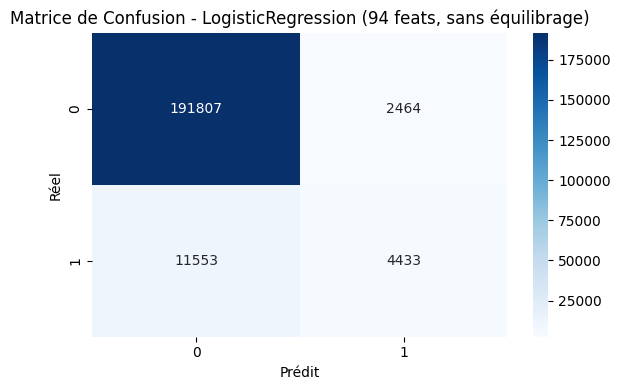


--- Modèle : RandomForest (Sur 94 feats, sans équilibrage explicite) ---
  Entraînement RandomForest...
  Entraînement terminé en 0:04:03.379343
  Évaluation RandomForest sur Test Set...

  Classification Report (Test - RandomForest):
              precision    recall  f1-score   support

           0       0.94      0.99      0.97    194271
           1       0.74      0.30      0.42     15986

    accuracy                           0.94    210257
   macro avg       0.84      0.64      0.70    210257
weighted avg       0.93      0.94      0.93    210257


  Matrice de Confusion (Test - RandomForest):
[[192629   1642]
 [ 11249   4737]]

  AUC ROC: 0.9253, AUC PR: 0.5796


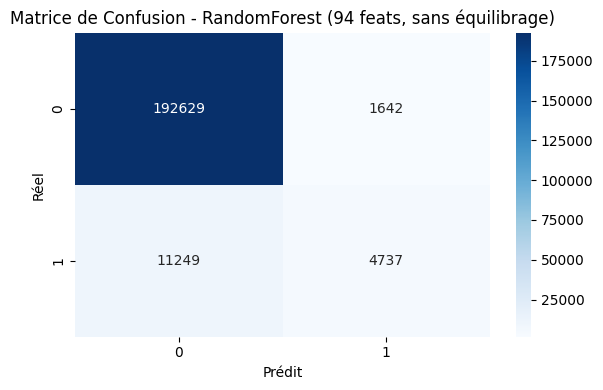


--- Modèle : GradientBoosting (Sur 94 feats, sans équilibrage explicite) ---
  Entraînement GradientBoosting...
  Entraînement terminé en 0:34:14.500370
  Évaluation GradientBoosting sur Test Set...

  Classification Report (Test - GradientBoosting):
              precision    recall  f1-score   support

           0       0.95      0.99      0.97    194271
           1       0.70      0.37      0.49     15986

    accuracy                           0.94    210257
   macro avg       0.83      0.68      0.73    210257
weighted avg       0.93      0.94      0.93    210257


  Matrice de Confusion (Test - GradientBoosting):
[[191767   2504]
 [ 10035   5951]]

  AUC ROC: 0.9268, AUC PR: 0.5909


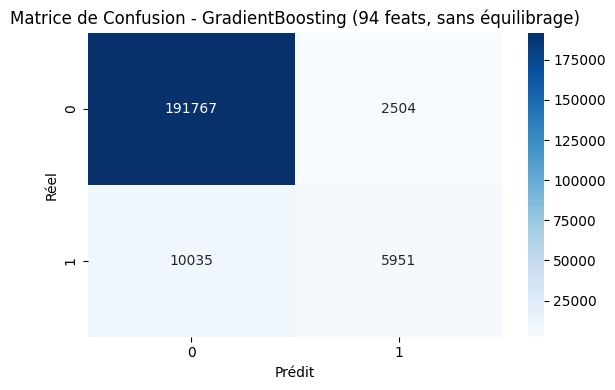



--- Résultats Finaux (94 Features, Sans Équilibrage Explicite) ---
                    AUC_ROC  AUC_PR  F1_Class1  Recall_Class1  \
GradientBoosting     0.9268  0.5909     0.4870         0.3723   
RandomForest         0.9253  0.5796     0.4236         0.2963   
LogisticRegression   0.9041  0.4985     0.3874         0.2773   

                    Precision_Class1  
GradientBoosting              0.7038  
RandomForest                  0.7426  
LogisticRegression            0.6427  


In [4]:
# =============================================================================
# CELLULE 4 : ÉTAPE VI - ENTRAÎNEMENT ET ÉVALUATION DES 3 MODÈLES
# =============================================================================

if data_ready_for_modeling:
    print(f"\n--- ÉTAPE VI: Entraînement et Évaluation (Sur Données Originales Déséquilibrées) ---")

    # Définir les modèles à tester (SANS class_weight='balanced' ici)
    model_configs = {
        "LogisticRegression": LogisticRegression(random_state=RANDOM_STATE, max_iter=1000, solver='liblinear'),
        "RandomForest": RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1, max_depth=15, min_samples_leaf=5),
        "GradientBoosting": GradientBoostingClassifier(n_estimators=100, random_state=RANDOM_STATE, max_depth=5)
        # Vous pouvez ajouter LightGBM ici si lgbm_available est True:
        # "LightGBM": lgb.LGBMClassifier(objective='binary', random_state=RANDOM_STATE, n_jobs=-1) if lgbm_available else None
    }

    results_baseline_94features = {} # Pour stocker les résultats de cette exécution

    # Boucle pour entraîner et évaluer
    for name, model in model_configs.items():
        if model is None: continue
        print(f"\n--- Modèle : {name} (Sur 94 feats, sans équilibrage explicite) ---")
        try:
            start_time = datetime.now()
            print(f"  Entraînement {name}...")
            # Entraîner sur X_train_scaled et y_train (cible originale déséquilibrée)
            model.fit(X_train_scaled.fillna(0), y_train) # y_train est y_train_final ici
            train_time = datetime.now() - start_time
            print(f"  Entraînement terminé en {train_time}")

            print(f"  Évaluation {name} sur Test Set...")
            X_test_eval = X_test_scaled.fillna(0)
            y_pred_test = model.predict(X_test_eval)
            y_proba_test = model.predict_proba(X_test_eval)[:, 1]

            print(f"\n  Classification Report (Test - {name}):")
            print(classification_report(y_test, y_pred_test, zero_division=0))
            print(f"\n  Matrice de Confusion (Test - {name}):")
            cm_model = confusion_matrix(y_test, y_pred_test)
            print(cm_model)

            # Calcul métriques clés
            roc_auc = roc_auc_score(y_test, y_proba_test) if len(np.unique(y_test)) > 1 else 0.5
            precision, recall, _ = precision_recall_curve(y_test, y_proba_test)
            pr_auc = auc(recall, precision)
            report_dict = classification_report(y_test, y_pred_test, output_dict=True, zero_division=0)

            print(f"\n  AUC ROC: {roc_auc:.4f}, AUC PR: {pr_auc:.4f}")

            # Stocker résultats
            results_baseline_94features[name] = {
                 'AUC_ROC': roc_auc, 'AUC_PR': pr_auc,
                 'F1_Class1': report_dict.get('1', {}).get('f1-score', 0),
                 'Recall_Class1': report_dict.get('1', {}).get('recall', 0),
                 'Precision_Class1': report_dict.get('1', {}).get('precision', 0)
            }
            # Afficher la matrice de confusion graphique
            try:
                plt.figure(figsize=(6,4))
                sns.heatmap(cm_model, annot=True, fmt='d', cmap='Blues') # Changé cmap pour variété
                plt.xlabel('Prédit')
                plt.ylabel('Réel')
                plt.title(f'Matrice de Confusion - {name} (94 feats, sans équilibrage)')
                plt.tight_layout()
                plt.show()
            except Exception as e: print(f"  Erreur affichage heatmap: {e}")

        except Exception as e:
            print(f"  ERREUR pour {name}: {e}")
            results_baseline_94features[name] = {'AUC_ROC': np.nan, 'AUC_PR': np.nan, 'F1_Class1': np.nan}

    # Afficher tableau récapitulatif pour cette exécution
    if len(results_baseline_94features) > 0:
        print("\n\n--- Résultats Finaux (94 Features, Sans Équilibrage Explicite) ---")
        results_df_baseline_94features = pd.DataFrame(results_baseline_94features).T
        pd.options.display.float_format = '{:.4f}'.format
        print(results_df_baseline_94features.sort_values(by='AUC_PR', ascending=False))

else:
    print("\nErreur: Données non prêtes pour l'étape VI (entraînement des modèles).")

# --- FIN Cellule 4 ---